### DATASET VUELOS

En esta notebook vamos a trabajar con un dataset con un dataset con datos relativa a [vuelos de un aeropuerto](https://www.kaggle.com/datasets/mahoora00135/flights)

 Comenzaremos conociendo nuestro dataset: tipo de datos contiene el dataset, estadistica descriptiva, detectar problemas como valores faltantes, establecer que tipo de relación existe entre las distintas variables, también debemos visualizar los datos. Este análisis nos permitira hacernos preguntas que puedan ser contestadas con el dataset como así plantear estrategias para poder resolver problemas presentes en él.

## Importamos librerías

In [175]:
# Importamos librerias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (LabelEncoder, OneHotEncoder)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    confusion_matrix, ConfusionMatrixDisplay,
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, roc_curve, auc
)
import os

**_Leemos el dataset 'flights.csv'_**

In [138]:
# Veo cual es la ruta donde se encuentra mi archivo
print(os.getcwd())

c:\Users\ayele\Documents\DS - Fundacion YPF\ProyectoFinal_DS


In [139]:
df_flight = pd.read_csv(r"c:/Users/ayele/Documents/DS - Fundacion YPF\ProyectoFinal_DS/flights.csv")

## Inspeccionamos los datos

Obtenemos información sobre nuestro dataset:

🤔 &nbsp; **_¿Como se ven las primeras 5 filas? ¿Cuantas filas y columnas posee? ¿Que tipos de datos contiene cada una de las columnas?_**

In [140]:
df_flight.head(5)

,id,year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,...,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour,name
0,0,2013,1,1,517.0,515,2.0,830.0,819,11.0,...,1545,N14228,EWR,IAH,227.0,1400,5,15,2013-01-01 05:00:00,United Air Lines Inc.
1,1,2013,1,1,533.0,529,4.0,850.0,830,20.0,...,1714,N24211,LGA,IAH,227.0,1416,5,29,2013-01-01 05:00:00,United Air Lines Inc.
2,2,2013,1,1,542.0,540,2.0,923.0,850,33.0,...,1141,N619AA,JFK,MIA,160.0,1089,5,40,2013-01-01 05:00:00,American Airlines Inc.
3,3,2013,1,1,544.0,545,-1.0,1004.0,1022,-18.0,...,725,N804JB,JFK,BQN,183.0,1576,5,45,2013-01-01 05:00:00,JetBlue Airways
4,4,2013,1,1,554.0,600,-6.0,812.0,837,-25.0,...,461,N668DN,LGA,ATL,116.0,762,6,0,2013-01-01 06:00:00,Delta Air Lines Inc.


In [141]:
df_flight.info()

<class 'pandas.DataFrame'>
RangeIndex: 336776 entries, 0 to 336775
Data columns (total 21 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   id              336776 non-null  int64  
 1   year            336776 non-null  int64  
 2   month           336776 non-null  int64  
 3   day             336776 non-null  int64  
 4   dep_time        328521 non-null  float64
 5   sched_dep_time  336776 non-null  int64  
 6   dep_delay       328521 non-null  float64
 7   arr_time        328063 non-null  float64
 8   sched_arr_time  336776 non-null  int64  
 9   arr_delay       327346 non-null  float64
 10  carrier         336776 non-null  str    
 11  flight          336776 non-null  int64  
 12  tailnum         334264 non-null  str    
 13  origin          336776 non-null  str    
 14  dest            336776 non-null  str    
 15  air_time        327346 non-null  float64
 16  distance        336776 non-null  int64  
 17  hour            33677

In [142]:
# Indentifico el nombre de las columnas
df_flight.columns

Index(['id', 'year', 'month', 'day', 'dep_time', 'sched_dep_time', 'dep_delay',
       'arr_time', 'sched_arr_time', 'arr_delay', 'carrier', 'flight',
       'tailnum', 'origin', 'dest', 'air_time', 'distance', 'hour', 'minute',
       'time_hour', 'name'],
      dtype='str')

**_Renombramos los nombres de las columnas para una mayor compresión_**

In [143]:
# Creo un diccionario con el nomrbe de las columnas
diccionario = {
    'id'            : 'id',
    'year'          : 'año',
    'month'         : 'mes',
    'day'           : 'día',
    'dep_time'      : 'hora_salida',
    'sched_dep_time': 'hora_salida_programada',
    'dep_delay'     : 'retraso_salida',
    'arr_time'      : 'hora_llegada',
    'sched_arr_time': 'hora_llegada_programada',
    'arr_delay'     : 'retraso_llegada',
    'carrier'       : 'aerolinea',
    'flight'        : 'vuelo',
    'tailnum'       : 'matricula',
    'origin'        : 'origen',
    'dest'          : 'destino',
    'air_time'      : 'tiempo_vuelo',
    'distance'      : 'distancia',
    'hour'          : 'hora',
    'minute'        : 'minuto',
    'time_hour'     : 'hora_fecha',
    'name'          : 'nombre'
}

In [144]:
df_flight.rename(columns = diccionario, inplace=True)
df_flight.columns

Index(['id', 'año', 'mes', 'día', 'hora_salida', 'hora_salida_programada',
       'retraso_salida', 'hora_llegada', 'hora_llegada_programada',
       'retraso_llegada', 'aerolinea', 'vuelo', 'matricula', 'origen',
       'destino', 'tiempo_vuelo', 'distancia', 'hora', 'minuto', 'hora_fecha',
       'nombre'],
      dtype='str')

In [145]:
# Elimino la columna 'id' para que no genere ruido al momento de aplicar el modelo
df_flight = df_flight.drop(['id'], axis=1)

In [146]:
df_flight.head(5)

,año,mes,día,hora_salida,hora_salida_programada,retraso_salida,hora_llegada,hora_llegada_programada,retraso_llegada,aerolinea,vuelo,matricula,origen,destino,tiempo_vuelo,distancia,hora,minuto,hora_fecha,nombre
0,2013,1,1,517.0,515,2.0,830.0,819,11.0,UA,1545,N14228,EWR,IAH,227.0,1400,5,15,2013-01-01 05:00:00,United Air Lines Inc.
1,2013,1,1,533.0,529,4.0,850.0,830,20.0,UA,1714,N24211,LGA,IAH,227.0,1416,5,29,2013-01-01 05:00:00,United Air Lines Inc.
2,2013,1,1,542.0,540,2.0,923.0,850,33.0,AA,1141,N619AA,JFK,MIA,160.0,1089,5,40,2013-01-01 05:00:00,American Airlines Inc.
3,2013,1,1,544.0,545,-1.0,1004.0,1022,-18.0,B6,725,N804JB,JFK,BQN,183.0,1576,5,45,2013-01-01 05:00:00,JetBlue Airways
4,2013,1,1,554.0,600,-6.0,812.0,837,-25.0,DL,461,N668DN,LGA,ATL,116.0,762,6,0,2013-01-01 06:00:00,Delta Air Lines Inc.


## Valores Faltantes

🤔 &nbsp; **_¿Hay valores faltantes en alguna de las columnas?_**

In [147]:
df_flight.isnull().sum()

año                           0
mes                           0
día                           0
hora_salida                8255
hora_salida_programada        0
retraso_salida             8255
hora_llegada               8713
hora_llegada_programada       0
retraso_llegada            9430
aerolinea                     0
vuelo                         0
matricula                  2512
origen                        0
destino                       0
tiempo_vuelo               9430
distancia                     0
hora                          0
minuto                        0
hora_fecha                    0
nombre                        0
dtype: int64

In [148]:
# Obtengo el maximo valor de datos faltantes y lo guardo en la variable dfNullSumMax
dfNullSumMax = df_flight.isnull().sum().max()
print(f"El valor máximo de datos faltantes es {dfNullSumMax}")

El valor máximo de datos faltantes es 9430


In [149]:
# Obtengo la cantidad de filas total y divido el maximo valor de datos faltantes por este numero y lo multiplico por 100

row_total= len(df_flight)

Null100 = (dfNullSumMax / row_total) * 100
print(f"El porcentaje máximo de datos faltantes es {Null100:.2f} %")

El porcentaje máximo de datos faltantes es 2.80 %


In [150]:
# Trae las filas que tienen almenos algun valor faltante en sus columnas
df_flight[df_flight.isnull().any(axis=1)]

,año,mes,día,hora_salida,hora_salida_programada,retraso_salida,hora_llegada,hora_llegada_programada,retraso_llegada,aerolinea,vuelo,matricula,origen,destino,tiempo_vuelo,distancia,hora,minuto,hora_fecha,nombre
471,2013,1,1,1525.0,1530,-5.0,1934.0,1805,NaN,MQ,4525,N719MQ,LGA,XNA,NaN,1147,15,30,2013-01-01 15:00:00,Envoy Air
477,2013,1,1,1528.0,1459,29.0,2002.0,1647,NaN,EV,3806,N17108,EWR,STL,NaN,872,14,59,2013-01-01 14:00:00,ExpressJet Airlines Inc.
615,2013,1,1,1740.0,1745,-5.0,2158.0,2020,NaN,MQ,4413,N739MQ,LGA,XNA,NaN,1147,17,45,2013-01-01 17:00:00,Envoy Air
643,2013,1,1,1807.0,1738,29.0,2251.0,2103,NaN,UA,1228,N31412,EWR,SAN,NaN,2425,17,38,2013-01-01 17:00:00,United Air Lines Inc.
725,2013,1,1,1939.0,1840,59.0,29.0,2151,NaN,9E,3325,N905XJ,JFK,DFW,NaN,1391,18,40,2013-01-01 18:00:00,Endeavor Air Inc.
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
336771,2013,9,30,NaN,1455,NaN,NaN,1634,NaN,9E,3393,NaN,JFK,DCA,NaN,213,14,55,2013-09-30 14:00:00,Endeavor Air Inc.
336772,2013,9,30,NaN,2200,NaN,NaN,2312,NaN,9E,3525,NaN,LGA,SYR,NaN,198,22,0,2013-09-30 22:00:00,Endeavor Air Inc.
336773,2013,9,30,NaN,1210,NaN,NaN,1330,NaN,MQ,3461,N535MQ,LGA,BNA,NaN,764,12,10,2013-09-30 12:00:00,Envoy Air
336774,2013,9,30,NaN,1159,NaN,NaN,1344,NaN,MQ,3572,N511MQ,LGA,CLE,NaN,419,11,59,2013-09-30 11:00:00,Envoy Air


 Debido a que el porcentaje de datos faltantes es inferior al '5%', decidimos desestimar dichas filas

In [151]:
df_flight = df_flight.dropna()

## Visualización de Datos

**_¿Cúal será la distrubición de nuestras variables predictoras?_**

In [152]:
# Chequeamos la cantidad de valores para cada valor único de la columna 'retraso_llegada'
df_flight['retraso_llegada'].value_counts()

retraso_llegada
-13.0      7177
-10.0      7088
-12.0      7046
-14.0      6975
-11.0      6863
           ... 
 505.0        1
 492.0        1
 572.0        1
 571.0        1
 1007.0       1
Name: count, Length: 577, dtype: int64

<Figure size 200x400 with 0 Axes>

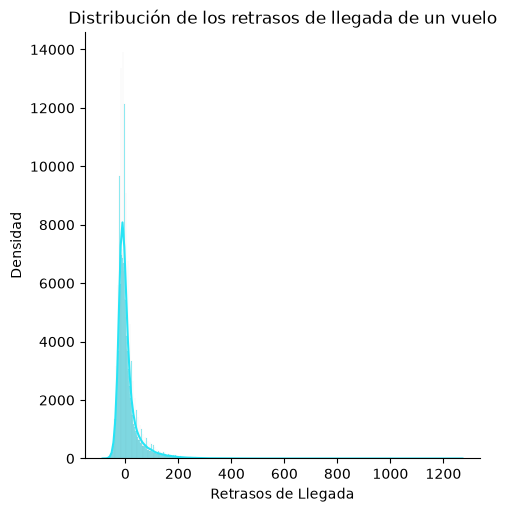

In [153]:
plt.figure(figsize=(2,4))
sns.displot(df_flight['retraso_llegada'],color='#27E4F5',kde=True)
plt.title('Distribución de los retrasos de llegada de un vuelo')
plt.xlabel('Retrasos de Llegada')
plt.ylabel('Densidad')
sns.despine()
plt.show()

Se observa que los datos posee un sesgo hacia la derecha, por lo que deberiamos aplicar transformación para normalidad la distribución de los mismos

In [154]:
df_flight['aerolinea'].value_counts()

aerolinea
UA    57782
B6    54049
EV    51108
DL    47658
AA    31947
MQ    25037
US    19831
9E    17294
WN    12044
VX     5116
FL     3175
AS      709
F9      681
YV      544
HA      342
OO       29
Name: count, dtype: int64

<Figure size 200x400 with 0 Axes>

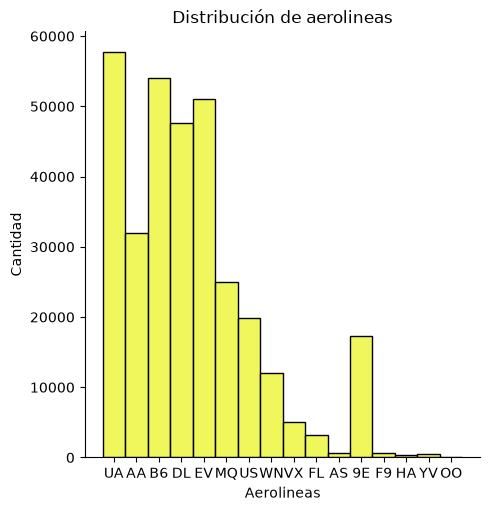

In [155]:
plt.figure(figsize=(2,4))
sns.displot(df_flight['aerolinea'],color='#EBF527')
plt.title('Distribución de aerolineas')
plt.xlabel('Aerolineas')
plt.ylabel('Cantidad')
sns.despine()
plt.show()

In [156]:
df_flight['destino'].value_counts()

destino
ATL    16837
ORD    16566
LAX    16026
BOS    15022
MCO    13967
       ...  
HDN       14
MTJ       14
SBN       10
ANC        8
LEX        1
Name: count, Length: 104, dtype: int64

## Agrego categorías de demora

In [157]:
# Defino una función para clasificar el nivel de puntualidad en base a los retraso de llegada de un determinado vuelo
def clasificar_puntualidad(retraso):
    if pd.isna(retraso):
        return 'Desconocido'
    elif retraso < 0:
        return 'Adelantado'   
    elif retraso == 0:
        return 'A tiempo'    
    elif retraso < 10:
        return 'Aceptable'    
    elif retraso <= 20:
        return 'Moderado'    
    elif retraso <= 30:
        return 'Severo'    
    else:
        return 'Crítico'

In [158]:
# Crear la única columna con el string de estado
df_flight['nivel_puntualidad'] = df_flight['retraso_llegada'].apply(clasificar_puntualidad)
df_flight.head(5)

,año,mes,día,hora_salida,hora_salida_programada,retraso_salida,hora_llegada,hora_llegada_programada,retraso_llegada,aerolinea,...,matricula,origen,destino,tiempo_vuelo,distancia,hora,minuto,hora_fecha,nombre,nivel_puntualidad
0,2013,1,1,517.0,515,2.0,830.0,819,11.0,UA,...,N14228,EWR,IAH,227.0,1400,5,15,2013-01-01 05:00:00,United Air Lines Inc.,Moderado
1,2013,1,1,533.0,529,4.0,850.0,830,20.0,UA,...,N24211,LGA,IAH,227.0,1416,5,29,2013-01-01 05:00:00,United Air Lines Inc.,Moderado
2,2013,1,1,542.0,540,2.0,923.0,850,33.0,AA,...,N619AA,JFK,MIA,160.0,1089,5,40,2013-01-01 05:00:00,American Airlines Inc.,Crítico
3,2013,1,1,544.0,545,-1.0,1004.0,1022,-18.0,B6,...,N804JB,JFK,BQN,183.0,1576,5,45,2013-01-01 05:00:00,JetBlue Airways,Adelantado
4,2013,1,1,554.0,600,-6.0,812.0,837,-25.0,DL,...,N668DN,LGA,ATL,116.0,762,6,0,2013-01-01 06:00:00,Delta Air Lines Inc.,Adelantado


In [159]:
# Tabla resumen con la cantidad de vuelos y el porcentaje segun el nivel de puntualidad
conteo = df_flight['nivel_puntualidad'].value_counts()
porcentaje = df_flight['nivel_puntualidad'].value_counts(normalize=True) * 100

tabla_puntualidad = pd.DataFrame(
    {'Cantidad de Vuelos': conteo, 'Porcentaje (%)': porcentaje.round(2)}
)

print('--- Distribución de Puntualidad ---')
print(tabla_puntualidad)

--- Distribución de Puntualidad ---
                   Cantidad de Vuelos  Porcentaje (%)
nivel_puntualidad                                    
Adelantado                     188933           57.72
Crítico                         51499           15.73
Aceptable                       38010           11.61
Moderado                        28136            8.60
Severo                          15359            4.69
A tiempo                         5409            1.65


In [160]:
# Agrupamos por aerolínea y obtenemos las matrículas únicas de sus aviones
# Usamos unique() para que no se repitan si un avión voló muchas veces
aviones_por_aerolinea = df_flight.groupby('aerolinea')['matricula'].unique()

print("--- Lista de Aerolíneas y sus Matrículas de Aviones ---")
for aerolinea, matriculas in aviones_por_aerolinea.items():
    print(f"\n Aerolínea: {aerolinea}")
    print(f"   Total de aviones únicos: {len(matriculas)}")
    print(f"   Matrículas: {list(matriculas)}")

--- Lista de Aerolíneas y sus Matrículas de Aviones ---

 Aerolínea: 9E
   Total de aviones únicos: 203
   Matrículas: ['N915XJ', 'N8444F', 'N920XJ', 'N8409N', 'N8631E', 'N913XJ', 'N904XJ', 'N934XJ', 'N910XJ', 'N931XJ', 'N8968E', 'N604LR', 'N8515F', 'N906XJ', 'N8894A', 'N908XJ', 'N925XJ', 'N8611A', 'N8598B', 'N836AY', 'N602LR', 'N916XJ', 'N924XJ', 'N8946A', 'N902XJ', 'N8869B', 'N901XJ', 'N841AY', 'N829AY', 'N918XJ', 'N930XJ', 'N812AY', 'N8432A', 'N8501F', 'N8908D', 'N8416B', 'N8390A', 'N933XJ', 'N601LR', 'N905XJ', 'N922XJ', 'N8646A', 'N600LR', 'N907XJ', 'N839AY', 'N820AY', 'N8412F', 'N8516C', 'N605LR', 'N919XJ', 'N8976E', 'N8794B', 'N914XJ', 'N8492C', 'N8877A', 'N8475B', 'N602XJ', 'N8940E', 'N826AY', 'N8924B', 'N8974C', 'N909XJ', 'N8884E', 'N8836A', 'N833AY', 'N917XJ', 'N903XJ', 'N8506C', 'N928XJ', 'N232PQ', 'N8525B', 'N827AY', 'N8914A', 'N8855A', 'N187PQ', 'N921XJ', 'N8710A', 'N937XJ', 'N8903A', 'N932XJ', 'N8948B', 'N8828D', 'N8659B', 'N8674A', 'N8932C', 'N929XJ', 'N8886A', 'N8970D', 

In [161]:
# Tabla cruzada entre Aerolínea y Estado de Vuelo
tabla_resumen = pd.crosstab(
    df_flight['aerolinea'], 
    df_flight['nivel_puntualidad'], 
    margins=True,          
    margins_name='Total Vuelos'
)

print("Resumen general de vuelos y estados por aerolínea ---")
print(tabla_resumen)

Resumen general de vuelos y estados por aerolínea ---
nivel_puntualidad  A tiempo  Aceptable  Adelantado  Crítico  Moderado  Severo  \
aerolinea                                                                       
9E                      227       1602       10430     3099      1229     707   
AA                      472       3244       20769     3827      2349    1286   
AS                        8         54         512       62        51      22   
B6                      926       6508       29514     9421      4895    2785   
DL                      782       5348       30463     5533      3752    1780   
EV                      801       5789       25823    11666      4375    2654   
F9                       18         86         271      171        84      51   
FL                       69        543        1211      665       445     242   
HA                        4         32         241       19        33      13   
MQ                      488       3297       12856     

## Seleccion de variables y codificación

Transformamos las columnas seleccionadas usando `pd.get_dummies`.

In [162]:
# 2. Target
y = df_flight['nivel_puntualidad'] 

In [163]:
# 3. Features sin fuga: solo lo conocido antes del vuelo
num_cols = ['mes', 'día', 'hora_salida_programada', 'hora_llegada_programada',
            'distancia', 'hora', 'minuto']
cat_cols = ['aerolinea', 'origen', 'destino']
X = df_flight[num_cols + cat_cols]

In [164]:
pre = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
])

In [165]:
modelo = Pipeline([
    ('pre', pre),
    ('clf', LogisticRegression(max_iter=1000, random_state=42)),
])

## REGRESIÓN O CLASIFICACIÓN

En base a nuestras variables, decidimos ir por un algoritmo de clasificación para predecir el retraso de un vuelo según la variable target 'nivel_puntualidad'

In [169]:
X_train, X_test, y_train_reg, y_test_reg = train_test_split(
    X, y, test_size=0.2, random_state=42)

Entrenamos dos modelos distintos y comparamos como se comportan:

- **Arbol de Decision**
- **Regresión Logistica**

In [176]:
modelo.fit(X_train, y_train_reg)
y_pred = modelo.predict(X_test)
print(accuracy_score(y_test_reg, y_pred))
print(classification_report(y_test_reg, y_pred))

0.5771956621353291
              precision    recall  f1-score   support

    A tiempo       0.00      0.00      0.00      1041
   Aceptable       0.00      0.00      0.00      7626
  Adelantado       0.58      0.99      0.73     37784
     Crítico       0.36      0.05      0.09     10348
    Moderado       0.00      0.00      0.00      5524
      Severo       0.00      0.00      0.00      3147

    accuracy                           0.58     65470
   macro avg       0.16      0.17      0.14     65470
weighted avg       0.39      0.58      0.44     65470



c:\Users\ayele\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\ayele\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\ayele\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(ave